In [1]:
import torch
import matplotlib.pyplot as plt

In [ ]:
class MyNetwork(torch.nn.Module):
    def __init__(self, input_size=1, hidden_size=20, output_size=1):
        super().__init__()
        self.fc1 = torch.nn.Linear(input_size, hidden_size)
        self.relu = torch.nn.ReLU()
        self.fc2 = torch.nn.Linear(hidden_size, output_size)
        self.hiddenlayer = torch.nn.Linear(hidden_size, hidden_size)
        self.sigmoid = torch.nn.Sigmoid()
        
        
        self._init_weights_kaiming()
    
    def _init_weights_xavier(self):
        torch.nn.init.xavier_uniform_(self.fc1.weight)
        torch.nn.init.zeros_(self.fc1.bias)
        torch.nn.init.xavier_uniform_(self.fc2.weight)
        torch.nn.init.zeros_(self.fc2.bias)

    def _init_weights_gaussian(self):
        torch.nn.init.normal_(self.fc1.weight, mean=0, std=0.1)
        torch.nn.init.zeros_(self.fc1.bias)
        torch.nn.init.normal_(self.fc2.weight, mean=0, std=0.1)
        torch.nn.init.zeros_(self.fc2.bias)

    def _init_weights_kaiming(self):
        torch.nn.init.kaiming_uniform_(self.fc1.weight, nonlinearity='relu')
        torch.nn.init.zeros_(self.fc1.bias)
        torch.nn.init.kaiming_uniform_(self.fc2.weight, nonlinearity='relu')
        torch.nn.init.zeros_(self.fc2.bias)

    def forward(self, x):
        x = self.fc1(x)
        x = self.sigmoid(x)
        x = self.hiddenlayer(x)
        x = self.sigmoid(x)
        x = self.fc2(x)
        return x

model = MyNetwork()
"""
kaiming initialization: N(0, 2/fan_in)
xavier initialization: N(0, 1/fan_in+fan_out)
gaussian initialization: N(0, 1)
"""

In [3]:
# class MyNetwork(torch.nn.Module):
#     def __init__(self, input_size=1, hidden_size=20, output_size=1):
#         super().__init__()
#         self.fc1 = torch.nn.Linear(input_size, hidden_size)
#         self.relu = torch.nn.ReLU()
#         self.fc2 = torch.nn.Linear(hidden_size, hidden_size)  # renamed from hiddenlayer
#         self.fc3 = torch.nn.Linear(hidden_size, output_size)
        
#         self._init_weights_gaussian()
    
#     def _init_weights_gaussian(self):
#         torch.nn.init.normal_(self.fc1.weight, mean=0, std=0.1)
#         torch.nn.init.zeros_(self.fc1.bias)
#         torch.nn.init.normal_(self.fc2.weight, mean=0, std=0.1)
#         torch.nn.init.zeros_(self.fc2.bias)
#         torch.nn.init.normal_(self.fc3.weight, mean=0, std=0.1)
#         torch.nn.init.zeros_(self.fc3.bias)

#     def forward(self, x):
#         x = self.fc1(x)
#         x = self.relu(x)
#         x = self.fc2(x)
#         x = self.relu(x)
#         x = self.fc3(x)
#         return x

# model = MyNetwork()

In [4]:
# make a list of numbers from 0 to 100
inputs = torch.arange(-100, 101, dtype=torch.float32).unsqueeze(1)
outputs = model(inputs)


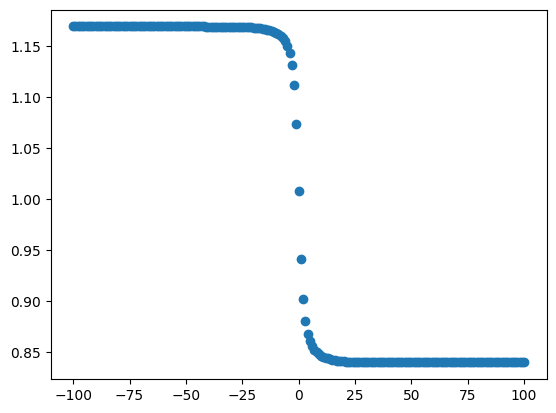

In [5]:
# plot inputs and outputs
plt.scatter(inputs.numpy(), outputs.detach().numpy())